# Combined NSW data: fixed-date model comparison
This additional version preserves the original notebook, data and earlier experiments.

It uses the combined CSV: whole original rows take priority on overlapping interval-start timestamps. Our 2023 observations extend the historical training period. Our July-August 2026 observations remain in the file but are excluded from this experiment.

**Validation:** five explicit date windows copied from the original-data experiment. Adding training rows cannot move these windows. Each fold trains on all available earlier days, including 2023.

**Test:** 1 April-30 June 2026 (91 days). This period has already been inspected in earlier trials; the present comparison is exploratory, not a new untouched final test. Model selection uses validation MAE, not test results.

**Forecast interpretation:** observed temperature and wind stand in for perfect weather forecasts. The lowest-10% classification threshold is statistical, not an official grid safety limit.

**Run:** open this notebook from the repository root or `notebooks/`, then run all cells. In Colab, upload this notebook and `NSW1_Combined_Original_Priority.csv`. Results are written to a separate `combined_fixed_validation` directory.


## 1. Configuration
Seed, input location, test cutoff and model settings. Model definitions and tuning grids are retained from upstream.


In [1]:
import os
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              HistGradientBoostingClassifier)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error, mean_absolute_percentage_error,
                             r2_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

# ---- Configuration ----
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

LOCAL_FILE = "NSW1_Combined_Original_Priority.csv"
candidate_paths = [Path("data/combined") / LOCAL_FILE,
                   Path("../data/combined") / LOCAL_FILE, Path(LOCAL_FILE)]
DATA_PATH = next((p.resolve() for p in candidate_paths if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Upload {LOCAL_FILE} or run from the repository root/notebooks directory.")
if DATA_PATH.parent.name == "combined" and DATA_PATH.parent.parent.name == "data":
    RESULT_BASE = DATA_PATH.parents[2] / "experiments/results"
else:
    RESULT_BASE = Path("results")

HOLDOUT_START = "2026-04-01"     # last 3 months (Apr, May, Jun 2026) are held out
MIDDAY_SLOTS  = range(20, 30)    # half-hour slots starting 10:00 to 14:30, i.e. 10:00-15:00
RISK_QUANTILE = 0.10             # a "risky" day is in the lowest 10% of training days
N_FOLDS       = 5                # cross-validation folds (as in Tutorial 5)
SYDNEY_LAT    = -33.95           # latitude of Sydney Airport, used for day length

# The two minimum-load targets compared throughout the notebook
TARGETS = {"day_min": "Daily minimum (any time)",
           "mid_min": "Midday minimum (10:00-15:00)"}

RESULTS_DIR = str(RESULT_BASE / "combined_fixed_validation")
os.makedirs(RESULTS_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def save_fig(name):
    """Save the current figure into results/ for use in the report."""
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150, bbox_inches="tight")

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

pandas 2.2.3 | scikit-learn 1.6.1


## 2. Load combined data
Read the combined CSV locally. No download or fallback to another dataset. Exclude dates from July 2026 onward before feature construction. Wind_speed_mps is a shared field name, but original weighted regional wind and our four-station mean retain different measurement definitions. See data/combined/row_provenance.csv and data/USER_GUIDE.html.


In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Interval_Start_AEST"])
excluded_future_rows = int((raw["Interval_Start_AEST"] >= "2026-07-01").sum())
raw = raw[raw["Interval_Start_AEST"] < "2026-07-01"].sort_values("Interval_Start_AEST").reset_index(drop=True)
required = {"Interval_Start_AEST", "TOD_Slot_0_47", "Demand_MW", "Sydney_Airport_Temp_C",
            "Wind_speed_mps", "DayOfWeek_Mon0", "Is_Weekend", "Is_NSW_Public_Holiday"}
assert required.issubset(raw.columns), "Missing required model inputs"
print(f"Loaded {len(raw):,} rows; excluded {excluded_future_rows:,} later rows from this experiment.")
raw.head(3)


Loaded 52,560 rows; excluded 2,976 later rows from this experiment.


,Interval_Start_AEST,TOD_Slot_0_47,Demand_MW,Sydney_Airport_Temp_C,Wind_speed_mps,DayOfWeek_Mon0,Is_Weekend,Is_NSW_Public_Holiday
0,2023-01-01 00:00:00,0,6826.395000,22.0,3.47250,6,1,1
1,2023-01-01 00:30:00,1,6645.366667,22.0,3.47250,6,1,1
2,2023-01-01 01:00:00,2,6384.128333,22.0,4.11555,6,1,1


## 3. Validate known continuous segments
Require unique timestamps, complete 48-slot days and nonmissing demand. The only permitted gap is January-June 2024. No missing months are fabricated or bridged by lag features.


In [3]:
ts = raw["Interval_Start_AEST"]
checks = {
    "No duplicate timestamps":       ts.duplicated().sum() == 0,
    "30-minute intervals except the documented 2024 gap":  (ts.diff().dropna().eq(pd.Timedelta(minutes=30)) | ((ts.shift(1).dropna() == pd.Timestamp("2023-12-31 23:30")) & (ts.iloc[1:] == pd.Timestamp("2024-07-01 00:00")))).all(),
    "Every day has 48 half-hours":   (raw.groupby(ts.dt.normalize()).size() == 48).all(),
    "No missing demand values":      raw["Demand_MW"].isna().sum() == 0,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values()), "Data validation failed: check the dataset before continuing."

missing = raw.isna().sum()
print("\nMissing weather values (handled later, inside the model pipeline):")
print(missing[(missing > 0) & (missing.index != "NSW_Holiday_Name")].to_string())
assert ts.is_monotonic_increasing
assert len(raw) == 52560


PASS  No duplicate timestamps
PASS  30-minute intervals except the documented 2024 gap
PASS  Every day has 48 half-hours
PASS  No missing demand values

Missing weather values (handled later, inside the model pipeline):
Sydney_Airport_Temp_C    607
Wind_speed_mps            95


## 4. Daily targets and observed weather
Construct the full-day minimum and 10:00-15:00 minimum, daily weather and calendar fields. Demand is a half-hour mean; weather timing and missing-value treatment follow the source tables. Temperature summaries use available readings, so incomplete days may miss true extrema.


In [4]:
hh = raw.copy()
hh["Date"] = hh["Interval_Start_AEST"].dt.normalize()
hh["Is_Midday"] = hh["TOD_Slot_0_47"].isin(MIDDAY_SLOTS)
by_day = hh.groupby("Date")

daily = pd.DataFrame({
    # ---- targets ----
    "day_min":  by_day["Demand_MW"].min(),
    "mid_min":  hh[hh["Is_Midday"]].groupby("Date")["Demand_MW"].min(),
    # hour of day when the daily minimum happened (slot / 2 = hour)
    "min_hour": hh.loc[by_day["Demand_MW"].idxmin(), ["Date", "TOD_Slot_0_47"]]
                  .set_index("Date")["TOD_Slot_0_47"] / 2,
    "day_mean": by_day["Demand_MW"].mean(),           # used only to build a lag feature
    # ---- daily weather (observed, standing in for a forecast) ----
    "Temp_mean":   by_day["Sydney_Airport_Temp_C"].mean(),
    "Temp_max":    by_day["Sydney_Airport_Temp_C"].max(),
    "Temp_min":    by_day["Sydney_Airport_Temp_C"].min(),
    "Temp_midday": hh[hh["Is_Midday"]].groupby("Date")["Sydney_Airport_Temp_C"].mean(),
    "Wind_mean":   by_day["Wind_speed_mps"].mean(),
    # ---- calendar ----
    "DayOfWeek":   by_day["DayOfWeek_Mon0"].first(),
    "Is_Weekend":  by_day["Is_Weekend"].first(),
    "Is_Holiday":  by_day["Is_NSW_Public_Holiday"].max(),
})
daily.index.name = "Date"

midday_share = daily["min_hour"].between(10, 14.5).mean()
print(f"{len(daily)} days | the daily minimum fell in the 10:00-15:00 window on {midday_share:.0%} of days")
daily.head()

1095 days | the daily minimum fell in the 10:00-15:00 window on 62% of days


,day_min,mid_min,min_hour,day_mean,Temp_mean,Temp_max,Temp_min,Temp_midday,Wind_mean,DayOfWeek,Is_Weekend,Is_Holiday
Date,,,,,,,,,,,,
2023-01-01,5516.006667,5516.006667,10.5,6426.492049,23.652174,28.0,20.0,26.400000,4.992616,6,1,1
2023-01-02,5254.505000,5254.505000,11.0,6534.954340,23.911111,28.0,19.0,27.300000,4.575523,0,0,1
2023-01-03,5954.418333,6342.620000,3.0,7289.063889,24.177778,28.0,22.0,27.200000,4.122701,1,0,0
2023-01-04,6195.823333,7086.398333,3.0,7322.717153,21.021739,25.0,19.0,20.444444,5.095328,2,0,0
2023-01-05,5890.920000,6301.335000,3.0,6831.582639,18.872340,21.0,17.0,20.200000,7.668436,3,0,0


## 5. Exploratory plots
Inspect the combined history and seasonal patterns. The test period is shown for retrospective context; do not use it for model or parameter selection. Timing associations do not prove a causal solar effect.


Lowest 8 days in the dataset:
            day_min  min_hour  Temp_mean  Is_Weekend  Is_Holiday
Date                                                            
2025-02-16   2581.8      12.0       19.1           1           0
2025-12-29   2797.1      12.5       19.3           0           0
2025-12-27   2973.2      12.5       18.1           1           0
2025-10-05   2979.4      11.5       21.8           1           0
2024-10-26   3078.6      12.5       16.0           1           0
2025-12-28   3088.2      13.5       19.0           1           0
2025-09-21   3146.1      11.5       16.9           1           0
2025-10-19   3192.9      12.0       21.1           1           0


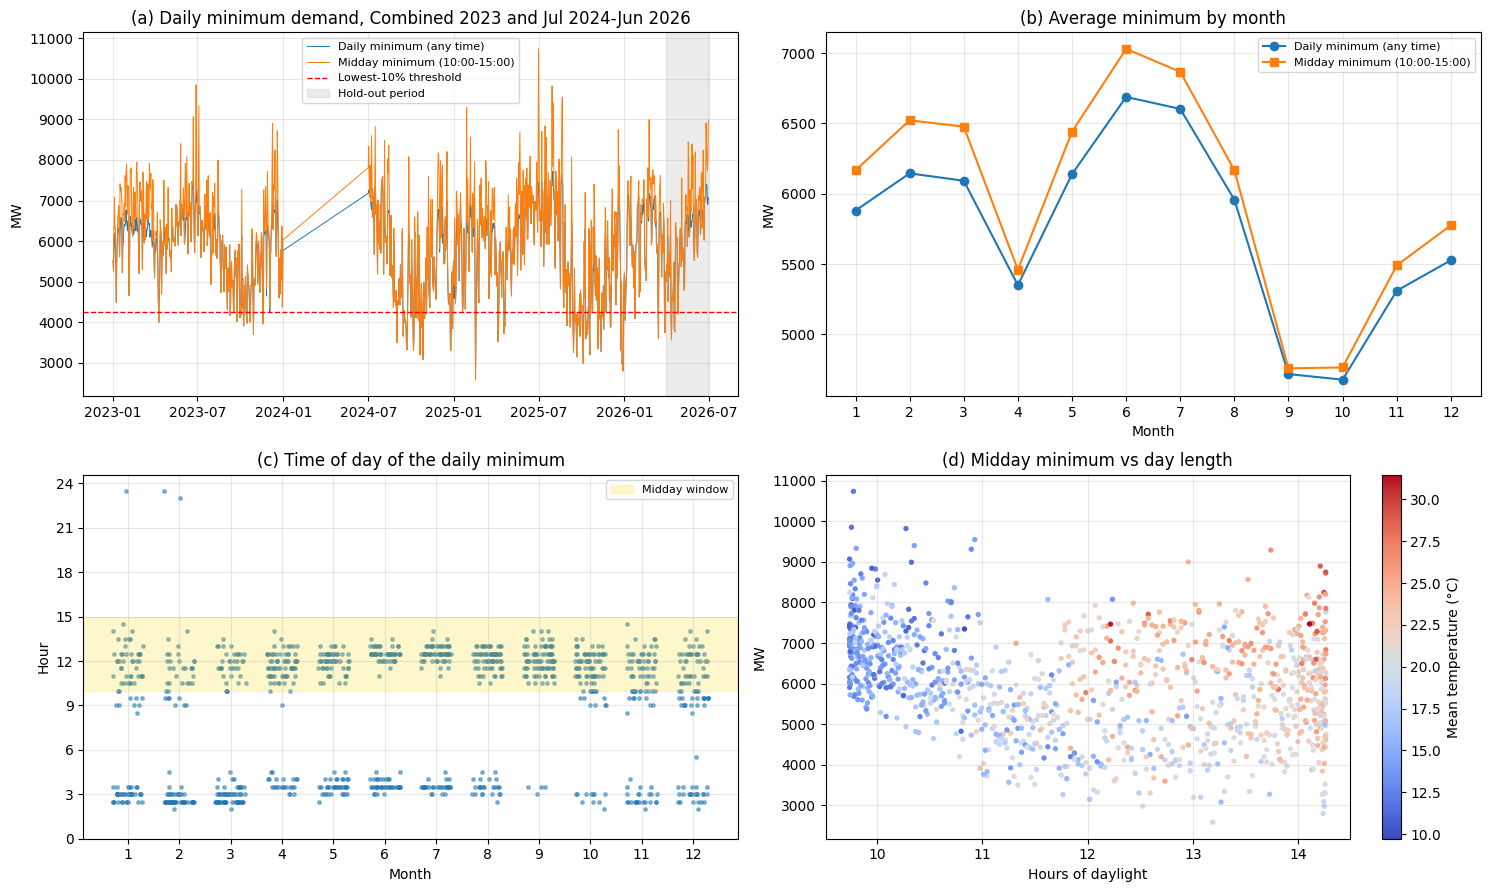

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) both targets over time, with the risk threshold computed from pre-hold-out days
pre = daily[daily.index < HOLDOUT_START]
ax = axes[0, 0]
for col, colour in [("day_min", "#1f77b4"), ("mid_min", "#ff7f0e")]:
    ax.plot(daily.index, daily[col], lw=0.7, color=colour, label=TARGETS[col])
ax.axhline(pre["day_min"].quantile(RISK_QUANTILE), color="red", ls="--", lw=1, label="Lowest-10% threshold")
ax.axvspan(pd.Timestamp(HOLDOUT_START), daily.index.max(), color="grey", alpha=0.15, label="Hold-out period")
ax.set(title="(a) Daily minimum demand, Combined 2023 and Jul 2024-Jun 2026", ylabel="MW"); ax.legend(fontsize=8)

# (b) monthly pattern
ax = axes[0, 1]
monthly = daily.groupby(daily.index.month)[["day_min", "mid_min"]].mean()
ax.plot(monthly.index, monthly["day_min"], marker="o", label=TARGETS["day_min"])
ax.plot(monthly.index, monthly["mid_min"], marker="s", label=TARGETS["mid_min"])
ax.set(title="(b) Average minimum by month", xlabel="Month", ylabel="MW", xticks=range(1, 13)); ax.legend(fontsize=8)

# (c) when does the minimum happen?
ax = axes[1, 0]
ax.scatter(daily.index.month + np.random.uniform(-0.3, 0.3, len(daily)), daily["min_hour"], s=6, alpha=0.5)
ax.axhspan(10, 15, color="gold", alpha=0.2, label="Midday window")
ax.set(title="(c) Time of day of the daily minimum", xlabel="Month", ylabel="Hour", xticks=range(1, 13),
       yticks=range(0, 25, 3)); ax.legend(fontsize=8)

# (d) day length vs minimum (day length formula explained in Section 6)
doy = daily.index.dayofyear
decl = np.radians(23.44) * np.sin(2 * np.pi * (284 + doy) / 365)
day_len = 24 / np.pi * np.arccos(-np.tan(np.radians(SYDNEY_LAT)) * np.tan(decl))
ax = axes[1, 1]
sc = ax.scatter(day_len, daily["mid_min"], c=daily["Temp_mean"], cmap="coolwarm", s=8)
plt.colorbar(sc, ax=ax, label="Mean temperature (°C)")
ax.set(title="(d) Midday minimum vs day length", xlabel="Hours of daylight", ylabel="MW")

plt.tight_layout(); save_fig("01_seasonality.png"); plt.show()

print("Lowest 8 days in the dataset:")
print(daily.nsmallest(8, "day_min")[["day_min", "min_hour", "Temp_mean", "Is_Weekend", "Is_Holiday"]].round(1))

## 6. Calendar-aware features
Build the original 26 features separately within each continuous daily segment. Shift and rolling features reset after the 2024 gap. Drop the first seven days of each segment (14 total). Same-day observed weather is an idealized input; calendar and historical-demand inputs are known in advance.


In [6]:
HDD_BASE, CDD_BASE = 18.0, 22.0

def build_features(d):
    """Create all model inputs for each day. Uses historical demand and calendar features plus idealized observed weather."""
    d = d.copy()
    doy = d.index.dayofyear

    # --- Seasonality: smooth yearly (1x) and half-yearly (2x) cycles ---
    for k in (1, 2):
        d[f"DOY_sin{k}"] = np.sin(2 * np.pi * k * doy / 365.25)
        d[f"DOY_cos{k}"] = np.cos(2 * np.pi * k * doy / 365.25)
    d["Month"] = d.index.month

    # --- Seasonality: hours of daylight in Sydney (standard solar declination formula) ---
    declination = np.radians(23.44) * np.sin(2 * np.pi * (284 + doy) / 365)
    d["Day_Length_h"] = 24 / np.pi * np.arccos(-np.tan(np.radians(SYDNEY_LAT)) * np.tan(declination))

    # --- Calendar: holidays are known in advance, so yesterday's and tomorrow's are both allowed ---
    d["Prev_Holiday"] = d["Is_Holiday"].shift(1).fillna(0).astype(int)
    d["Next_Holiday"] = d["Is_Holiday"].shift(-1).fillna(0).astype(int)
    d["Xmas_Break"] = (((d.index.month == 12) & (d.index.day >= 24)) |
                       ((d.index.month == 1) & (d.index.day <= 2))).astype(int)

    # --- Weather: heating and cooling degrees from daily mean temperature ---
    d["HDD"] = np.maximum(HDD_BASE - d["Temp_mean"], 0)
    d["CDD"] = np.maximum(d["Temp_mean"] - CDD_BASE, 0)

    # --- Recent minimums: shift(1) = yesterday, so nothing from the forecast day itself is used ---
    for t in TARGETS:
        d[f"{t}_lag1"] = d[t].shift(1)
        d[f"{t}_lag7"] = d[t].shift(7)
        d[f"{t}_roll7"] = d[t].shift(1).rolling(7).mean()
    d["day_mean_lag1"] = d["day_mean"].shift(1)
    return d

FEATURES = [
    "DOY_sin1", "DOY_cos1", "DOY_sin2", "DOY_cos2", "Day_Length_h", "Month",
    "DayOfWeek", "Is_Weekend", "Is_Holiday", "Prev_Holiday", "Next_Holiday", "Xmas_Break",
    "Temp_mean", "Temp_max", "Temp_min", "Temp_midday", "HDD", "CDD", "Wind_mean",
    "day_min_lag1", "day_min_lag7", "day_min_roll7",
    "mid_min_lag1", "mid_min_lag7", "mid_min_roll7", "day_mean_lag1",
]

segment_id = daily.index.to_series().diff().ne(pd.Timedelta(days=1)).cumsum()
feat = pd.concat([build_features(part) for _, part in daily.groupby(segment_id)]).sort_index()
# The first 7 days have no "last week" value, so they are removed
feat = feat.dropna(subset=["day_min_lag7", "mid_min_lag7", "day_min_roll7"])
print(f"{len(FEATURES)} features | {len(feat)} usable days (first week of each continuous segment removed)")
feat[FEATURES].describe().T[["mean", "min", "max"]].round(2)
assert len(feat) == 1081
assert pd.Timestamp("2024-07-01") not in feat.index
assert pd.Timestamp("2024-07-08") in feat.index


26 features | 1081 usable days (first week of each continuous segment removed)


## 7. Training and test split
There are 990 training days before April 2026 and 91 test days in April-June. Classification thresholds are computed from the training data only. The thresholds may differ from earlier datasets. July-August 2026 is excluded, not used to predict earlier dates.


In [7]:
train = feat[feat.index < HOLDOUT_START]
hold  = feat[feat.index >= HOLDOUT_START]
X_train, X_hold = train[FEATURES], hold[FEATURES]

# Risk threshold for each target, from training days only
THRESHOLDS = {t: train[t].quantile(RISK_QUANTILE) for t in TARGETS}

print(f"Training: {len(train)} days ({train.index.min():%d %b %Y} to {train.index.max():%d %b %Y})")
print(f"Hold-out: {len(hold)} days ({hold.index.min():%d %b %Y} to {hold.index.max():%d %b %Y})\n")
for t, name in TARGETS.items():
    n_tr = (train[t] < THRESHOLDS[t]).sum()
    n_ho = (hold[t] < THRESHOLDS[t]).sum()
    print(f"{name}: risky if below {THRESHOLDS[t]:,.0f} MW | risky days: {n_tr} in training, {n_ho} in hold-out")

same = ((train["day_min"] < THRESHOLDS["day_min"]) == (train["mid_min"] < THRESHOLDS["mid_min"])).all()
print(f"\nThe two targets flag exactly the same risky days: {same}")
assert len(train) == 990 and len(hold) == 91


Training: 990 days (08 Jan 2023 to 31 Mar 2026)
Hold-out: 91 days (01 Apr 2026 to 30 Jun 2026)

Daily minimum (any time): risky if below 4,258 MW | risky days: 99 in training, 5 in hold-out
Midday minimum (10:00-15:00): risky if below 4,258 MW | risky days: 99 in training, 5 in hold-out

The two targets flag exactly the same risky days: True


## 8. Fixed validation dates
Each of the five validation windows has the same dates as the original-data experiment, 105 days each. Training expands using strictly earlier available dates, including 2023. The fixed splitter is shared by predictions and GridSearchCV. Standardization and imputation are fitted inside each training fold.


In [8]:
VALIDATION_WINDOWS = [
    ("2024-10-23", "2025-02-04"),
    ("2025-02-05", "2025-05-20"),
    ("2025-05-21", "2025-09-02"),
    ("2025-09-03", "2025-12-16"),
    ("2025-12-17", "2026-03-31"),
]

class FixedDateSplit:
    def get_n_splits(self, X=None, y=None, groups=None):
        return len(VALIDATION_WINDOWS)

    def split(self, X, y=None, groups=None):
        dates = pd.DatetimeIndex(X.index)
        assert dates.is_unique and dates.is_monotonic_increasing
        for start, end in VALIDATION_WINDOWS:
            tr = np.flatnonzero(dates < pd.Timestamp(start))
            va = np.flatnonzero((dates >= pd.Timestamp(start)) & (dates <= pd.Timestamp(end)))
            expected = pd.date_range(start, end, freq="D")
            assert len(tr) > 0 and dates[va].equals(expected), "Validation dates are missing or changed"
            assert dates[tr].max() < dates[va].min()
            yield tr, va

tscv = FixedDateSplit()
fold_manifest = []
for k, (tr, va) in enumerate(tscv.split(X_train), 1):
    fold_manifest.append({"fold": k, "train_days": len(tr), "train_start": str(X_train.index[tr[0]].date()),
                          "train_end": str(X_train.index[tr[-1]].date()),
                          "validation_start": str(X_train.index[va[0]].date()),
                          "validation_end": str(X_train.index[va[-1]].date()), "validation_days": len(va)})
assert [r["train_days"] for r in fold_manifest] == [465, 570, 675, 780, 885]
pd.DataFrame(fold_manifest).to_csv(os.path.join(RESULTS_DIR, "fixed_validation_windows.csv"), index=False)

for i, (tr, va) in enumerate(tscv.split(X_train), 1):
    print(f"Fold {i}: train {X_train.index[tr[0]]:%d %b %Y} to {X_train.index[tr[-1]]:%d %b %Y} "
          f"({len(tr)} days) -> validate {X_train.index[va[0]]:%d %b %Y} to {X_train.index[va[-1]]:%d %b %Y}")

def cv_predict(model, y, proba=False):
    """Fit a fresh copy of the model on each fold's past and predict its validation block.
    Returns a Series of out-of-fold predictions (NaN for days never used for validation)
    and the fold number of each prediction."""
    pred = pd.Series(np.nan, index=y.index)
    fold = pd.Series(np.nan, index=y.index)
    for k, (tr, va) in enumerate(tscv.split(X_train), 1):
        m = clone(model).fit(X_train.iloc[tr], y.iloc[tr])
        pred.iloc[va] = m.predict_proba(X_train.iloc[va])[:, 1] if proba else m.predict(X_train.iloc[va])
        fold.iloc[va] = k
    return pred, fold

def regression_scores(y_true, y_pred):
    return {"MAE (MW)": mean_absolute_error(y_true, y_pred),
            "RMSE (MW)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
            "R2": r2_score(y_true, y_pred)}

Fold 1: train 08 Jan 2023 to 22 Oct 2024 (465 days) -> validate 23 Oct 2024 to 04 Feb 2025
Fold 2: train 08 Jan 2023 to 04 Feb 2025 (570 days) -> validate 05 Feb 2025 to 20 May 2025
Fold 3: train 08 Jan 2023 to 20 May 2025 (675 days) -> validate 21 May 2025 to 02 Sep 2025
Fold 4: train 08 Jan 2023 to 02 Sep 2025 (780 days) -> validate 03 Sep 2025 to 16 Dec 2025
Fold 5: train 08 Jan 2023 to 16 Dec 2025 (885 days) -> validate 17 Dec 2025 to 31 Mar 2026


## 9. Simple forecasting baselines
Compare yesterday, the same day last week, and training-set seasonal averages on the same fixed validation dates.


In [9]:
class ColumnBaseline(BaseEstimator, RegressorMixin):
    """Predicts by copying one input column (e.g. yesterday's minimum). Nothing is learned."""
    def __init__(self, column="day_min_lag1"):
        self.column = column
    def fit(self, X, y):
        return self
    def predict(self, X):
        return X[self.column].to_numpy()

class SeasonalAverage(BaseEstimator, RegressorMixin):
    """Predicts the average training value for each (month, day type) combination."""
    @staticmethod
    def _key(X):
        day_type = np.where(X["Is_Holiday"] == 1, 2, X["Is_Weekend"])   # 0 weekday, 1 weekend, 2 holiday
        return pd.MultiIndex.from_arrays([X["Month"].to_numpy(), day_type])
    def fit(self, X, y):
        s = pd.Series(np.asarray(y), index=self._key(X))
        self.table_ = s.groupby(level=[0, 1]).mean()
        self.month_ = s.groupby(level=0).mean()      # fallback if a combination was never seen
        self.overall_ = s.mean()
        return self
    def predict(self, X):
        key = self._key(X)
        out = self.table_.reindex(key).to_numpy()
        fallback = self.month_.reindex(key.get_level_values(0)).fillna(self.overall_).to_numpy()
        return np.where(np.isnan(out), fallback, out)

def make_baselines(t):
    return {"Baseline: same as yesterday":   ColumnBaseline(f"{t}_lag1"),
            "Baseline: same day last week":  ColumnBaseline(f"{t}_lag7"),
            "Baseline: seasonal average":    SeasonalAverage()}

cv_rows, oof = [], {}       # oof[(target, model)] stores out-of-fold predictions for later sections
for t, tname in TARGETS.items():
    y = train[t]
    for name, model in make_baselines(t).items():
        pred, fold = cv_predict(model, y)
        mask = pred.notna()
        oof[(t, name)] = pred
        cv_rows.append({"Target": tname, "Model": name, **regression_scores(y[mask], pred[mask])})

pd.DataFrame(cv_rows).round(2)

,Target,Model,MAE (MW),RMSE (MW),MAPE (%),R2
0,Daily minimum (any time),Baseline: same as yesterday,625.77,824.07,11.94,0.43
1,Daily minimum (any time),Baseline: same day last week,866.72,1132.21,16.83,-0.08
2,Daily minimum (any time),Baseline: seasonal average,665.67,867.85,13.36,0.37
3,Midday minimum (10:00-15:00),Baseline: same as yesterday,868.49,1109.81,15.28,0.32
4,Midday minimum (10:00-15:00),Baseline: same day last week,1144.72,1482.21,20.81,-0.22
5,Midday minimum (10:00-15:00),Baseline: seasonal average,891.01,1145.67,16.82,0.27


## 10. Compare and tune regression models
Compare Ridge (alpha=10), Random Forest, default Gradient Boosting and tuned Gradient Boosting. Retain the original parameter grid, seed and preprocessing. Select the model using fixed-date cross-validation MAE only. Tuning and the reported CV score share folds, so tuned CV scores are model-selection estimates rather than an independent validation.


In [10]:
def make_models():
    return {
        # Ridge = linear regression with a penalty on large weights (see the note above)
        "Linear Regression (Ridge)": Pipeline([("impute", SimpleImputer(strategy="median")),
                                               ("scale", StandardScaler()),
                                               ("model", Ridge(alpha=10.0))]),
        "Random Forest": Pipeline([("impute", SimpleImputer(strategy="median")),
                                   ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                                   n_jobs=-1, random_state=RANDOM_STATE))]),
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                                           random_state=RANDOM_STATE),
    }

PARAM_GRID = {"learning_rate": [0.03, 0.1], "max_iter": [200, 500],
              "max_leaf_nodes": [7, 15], "min_samples_leaf": [10, 20]}

tuned = {}   # best tuned Gradient Boosting model for each target
for t, tname in TARGETS.items():
    y = train[t]
    for name, model in make_models().items():
        pred, fold = cv_predict(model, y)
        mask = pred.notna()
        oof[(t, name)] = pred
        cv_rows.append({"Target": tname, "Model": name, **regression_scores(y[mask], pred[mask])})

    # Tune Gradient Boosting with the same time-series folds
    search = GridSearchCV(HistGradientBoostingRegressor(random_state=RANDOM_STATE), PARAM_GRID,
                          cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y)
    tuned[t] = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **search.best_params_)
    pred, fold = cv_predict(tuned[t], y)
    mask = pred.notna()
    oof[(t, "Gradient Boosting (tuned)")] = pred
    cv_rows.append({"Target": tname, "Model": "Gradient Boosting (tuned)", **regression_scores(y[mask], pred[mask])})
    print(f"{tname}: best settings {search.best_params_}")

cv_table = pd.DataFrame(cv_rows).sort_values(["Target", "MAE (MW)"]).reset_index(drop=True)
cv_table.to_csv(os.path.join(RESULTS_DIR, "cv_regression_results.csv"), index=False)
cv_table.round(2)

Daily minimum (any time): best settings {'learning_rate': 0.03, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 10}
Midday minimum (10:00-15:00): best settings {'learning_rate': 0.03, 'max_iter': 200, 'max_leaf_nodes': 7, 'min_samples_leaf': 10}


,Target,Model,MAE (MW),RMSE (MW),MAPE (%),R2
0,Daily minimum (any time),Linear Regression (Ridge),433.27,565.75,8.73,0.73
1,Daily minimum (any time),Gradient Boosting (tuned),453.18,592.65,9.03,0.71
2,Daily minimum (any time),Gradient Boosting,466.11,620.07,9.33,0.68
3,Daily minimum (any time),Random Forest,479.25,618.16,9.55,0.68
4,Daily minimum (any time),Baseline: same as yesterday,625.77,824.07,11.94,0.43
5,Daily minimum (any time),Baseline: seasonal average,665.67,867.85,13.36,0.37
6,Daily minimum (any time),Baseline: same day last week,866.72,1132.21,16.83,-0.08
7,Midday minimum (10:00-15:00),Linear Regression (Ridge),606.40,770.62,11.21,0.67
8,Midday minimum (10:00-15:00),Gradient Boosting (tuned),610.01,792.57,11.26,0.65
9,Midday minimum (10:00-15:00),Gradient Boosting,626.72,818.87,11.55,0.63


Best model for Daily minimum (any time): Linear Regression (Ridge)
Best model for Midday minimum (10:00-15:00): Linear Regression (Ridge)


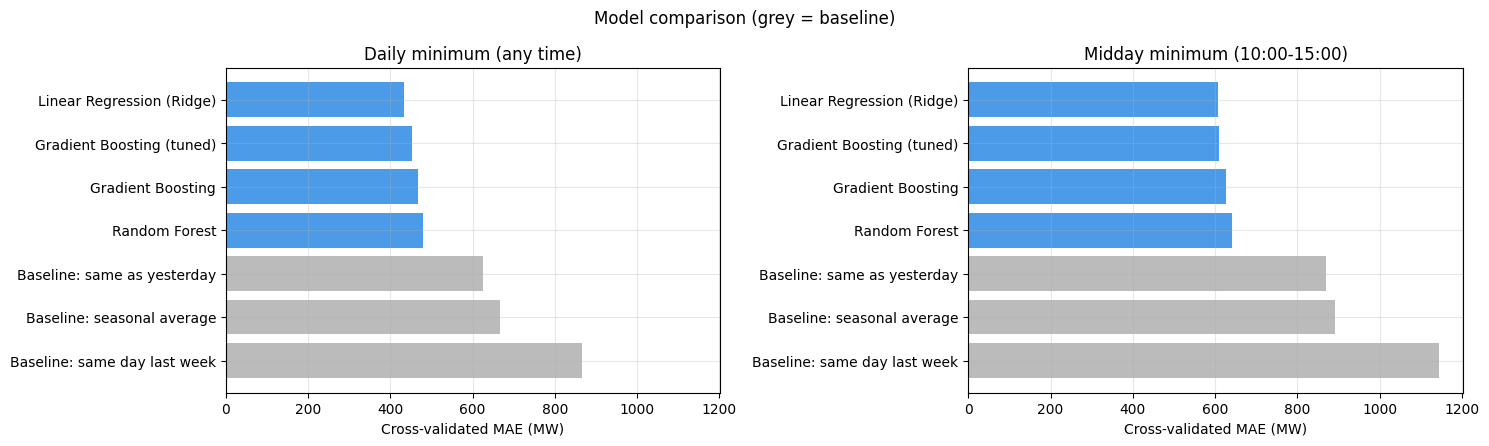

In [11]:
# Chart: cross-validated MAE for every model, both targets side by side (lower is better)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for ax, (t, tname) in zip(axes, TARGETS.items()):
    sub = cv_table[cv_table["Target"] == tname].sort_values("MAE (MW)")
    colours = ["#bbbbbb" if m.startswith("Baseline") else "#4c9be8" for m in sub["Model"]]
    ax.barh(sub["Model"], sub["MAE (MW)"], color=colours)
    ax.invert_yaxis(); ax.set(title=tname, xlabel="Cross-validated MAE (MW)")
fig.suptitle("Model comparison (grey = baseline)")
plt.tight_layout(); save_fig("02_model_comparison.png"); plt.show()

# Pick the best ML model (lowest CV MAE) for each target
best_reg = {}
for t, tname in TARGETS.items():
    sub = cv_table[(cv_table["Target"] == tname) & ~cv_table["Model"].str.startswith("Baseline")]
    best_reg[t] = sub.iloc[0]["Model"]
    print(f"Best model for {tname}: {best_reg[t]}")

## 11. Seasonal validation performance
Evaluate the validation-selected model by month and season using predictions on the fixed windows. Positive bias means the minimum is predicted too high.


Season                                                   Spring  ...  Winter
Target                       Model                               ...        
Daily minimum (any time)     Baseline: seasonal average   713.0  ...   620.0
                             Linear Regression (Ridge)    496.0  ...   441.0
Midday minimum (10:00-15:00) Baseline: seasonal average   886.0  ...   850.0
                             Linear Regression (Ridge)    601.0  ...   643.0

[4 rows x 4 columns]

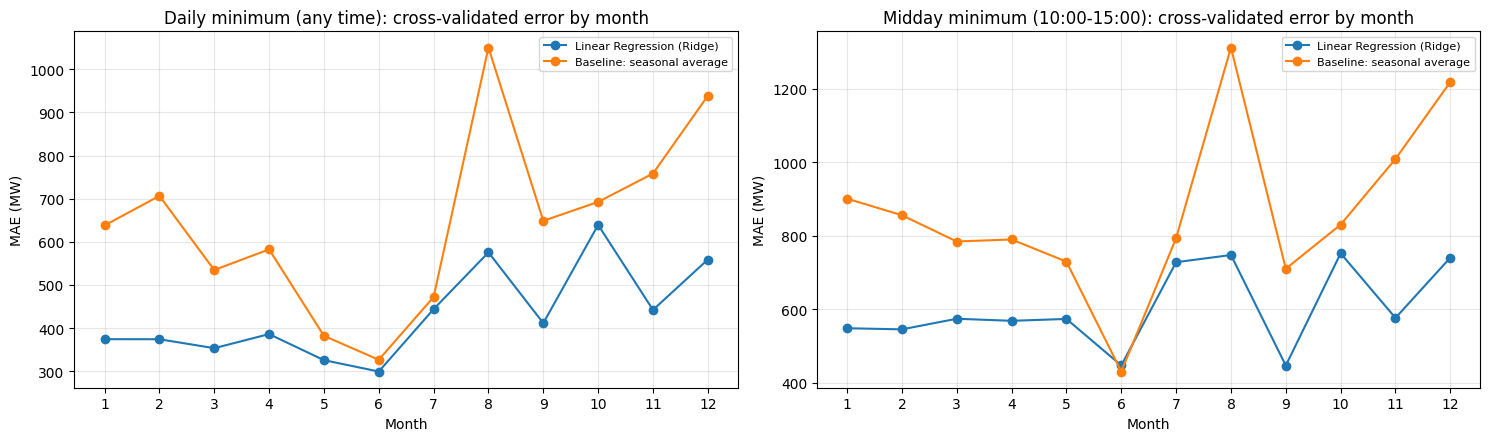

In [12]:
SEASONS = {12: "Summer", 1: "Summer", 2: "Summer", 3: "Autumn", 4: "Autumn", 5: "Autumn",
           6: "Winter", 7: "Winter", 8: "Winter", 9: "Spring", 10: "Spring", 11: "Spring"}
season_order = ["Spring", "Summer", "Autumn", "Winter"]

season_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (t, tname) in zip(axes, TARGETS.items()):
    y = train[t]
    for model_name in [best_reg[t], "Baseline: seasonal average"]:
        p = oof[(t, model_name)].dropna()
        err = (p - y[p.index])
        season = pd.Series(p.index.month.map(SEASONS), index=p.index)
        for s in season_order:
            e = err[season == s]
            season_rows.append({"Target": tname, "Model": model_name, "Season": s, "Days": len(e),
                                "MAE (MW)": e.abs().mean(), "Bias (MW)": e.mean()})
        # monthly MAE line for the chart
        ax.plot(range(1, 13), err.abs().groupby(p.index.month).mean().reindex(range(1, 13)),
                marker="o", label=model_name)
    ax.set(title=f"{tname}: cross-validated error by month", xlabel="Month", ylabel="MAE (MW)",
           xticks=range(1, 13))
    ax.legend(fontsize=8)
plt.tight_layout(); save_fig("03_error_by_month.png"); plt.show()

season_table = pd.DataFrame(season_rows)
season_table.to_csv(os.path.join(RESULTS_DIR, "seasonal_performance.csv"), index=False)
season_table.pivot_table(index=["Target", "Model"], columns="Season",
                         values="MAE (MW)")[season_order].round(0)

In [13]:
# Bias by season for the best model (positive = predicted minimum too high = risk underestimated)
season_table[~season_table["Model"].str.startswith("Baseline")].pivot_table(
    index="Target", columns="Season", values="Bias (MW)")[season_order].round(0)

Season,Spring,Summer,Autumn,Winter
Target,,,,
Daily minimum (any time),215.0,179.0,165.0,-3.0
Midday minimum (10:00-15:00),214.0,337.0,304.0,16.0


## 12. Low-load classification
Compare the original classification approaches on the same fixed validation windows. The full-training lowest-10% threshold is retained for comparability; it is not re-estimated within each fold. Treat CV classification as a retrospective fixed-label comparison, not a fully as-of-date operational backtest.


In [14]:
class ThresholdBaseline(BaseEstimator, ClassifierMixin):
    """Flags a day as risky if yesterday's minimum was below the threshold."""
    def __init__(self, column="day_min_lag1", threshold=0.0):
        self.column, self.threshold = column, threshold
    def fit(self, X, y):
        self.classes_ = np.array([0, 1]); return self
    def predict(self, X):
        return (X[self.column] < self.threshold).astype(int).to_numpy()

def make_classifiers(t):
    return {
        "Logistic Regression": Pipeline([("impute", SimpleImputer(strategy="median")),
                                         ("scale", StandardScaler()),
                                         ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                                                      C=0.5))]),
        "Gradient Boosting classifier": HistGradientBoostingClassifier(
            class_weight="balanced", max_iter=200, learning_rate=0.05, max_leaf_nodes=7,
            min_samples_leaf=10, random_state=RANDOM_STATE),
    }

def classification_scores(y_true, flag, prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, flag, labels=[0, 1]).ravel()
    return {"Risky days": int(y_true.sum()), "Caught": int(tp), "Missed": int(fn), "False alarms": int(fp),
            "Recall": recall_score(y_true, flag, zero_division=0),
            "Precision": precision_score(y_true, flag, zero_division=0),
            "F1": f1_score(y_true, flag, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, prob) if prob is not None and len(set(y_true)) == 2 else np.nan}

clf_rows, oof_flags = [], {}
for t, tname in TARGETS.items():
    thr = THRESHOLDS[t]
    y_cls = (train[t] < thr).astype(int)
    mask = oof[(t, best_reg[t])].notna()          # the days covered by the validation folds

    # Baseline
    base_flag, _ = cv_predict(ThresholdBaseline(f"{t}_lag1", thr), y_cls)
    clf_rows.append({"Target": tname, "Model": "Baseline: yesterday was risky",
                     **classification_scores(y_cls[mask], base_flag[mask].astype(int))})

    # Regression-based: flag when the predicted minimum is below the threshold.
    # A lower predicted value means more risk, so -prediction works as a risk score for ROC-AUC.
    reg_pred = oof[(t, best_reg[t])]
    reg_flag = (reg_pred < thr).astype(int)
    oof_flags[(t, "Regression-based")] = reg_flag[mask]
    clf_rows.append({"Target": tname, "Model": f"Regression-based ({best_reg[t]})",
                     **classification_scores(y_cls[mask], reg_flag[mask], -reg_pred[mask])})

    # Dedicated classifiers
    for name, model in make_classifiers(t).items():
        prob, _ = cv_predict(model, y_cls, proba=True)
        flag = (prob[mask] >= 0.5).astype(int)
        oof_flags[(t, name)] = flag
        clf_rows.append({"Target": tname, "Model": name, **classification_scores(y_cls[mask], flag, prob[mask])})

clf_table = pd.DataFrame(clf_rows).sort_values(["Target", "F1"], ascending=[True, False]).reset_index(drop=True)
clf_table.to_csv(os.path.join(RESULTS_DIR, "cv_classification_results.csv"), index=False)
clf_table.round(3)

,Target,Model,Risky days,Caught,Missed,False alarms,Recall,Precision,F1,ROC-AUC
0,Daily minimum (any time),Logistic Regression,66,47,19,26,0.712,0.644,0.676,0.942
1,Daily minimum (any time),Baseline: yesterday was risky,66,38,28,29,0.576,0.567,0.571,NaN
2,Daily minimum (any time),Gradient Boosting classifier,66,32,34,14,0.485,0.696,0.571,0.930
3,Daily minimum (any time),Regression-based (Linear Regression (Ridge)),66,16,50,3,0.242,0.842,0.376,0.964
4,Midday minimum (10:00-15:00),Logistic Regression,66,47,19,26,0.712,0.644,0.676,0.942
5,Midday minimum (10:00-15:00),Baseline: yesterday was risky,66,38,28,29,0.576,0.567,0.571,NaN
6,Midday minimum (10:00-15:00),Gradient Boosting classifier,66,32,34,14,0.485,0.696,0.571,0.930
7,Midday minimum (10:00-15:00),Regression-based (Linear Regression (Ridge)),66,22,44,4,0.333,0.846,0.478,0.963


Best flagging approach for Daily minimum (any time): Logistic Regression (recall 0.71, precision 0.64)
Best flagging approach for Midday minimum (10:00-15:00): Logistic Regression (recall 0.71, precision 0.64)


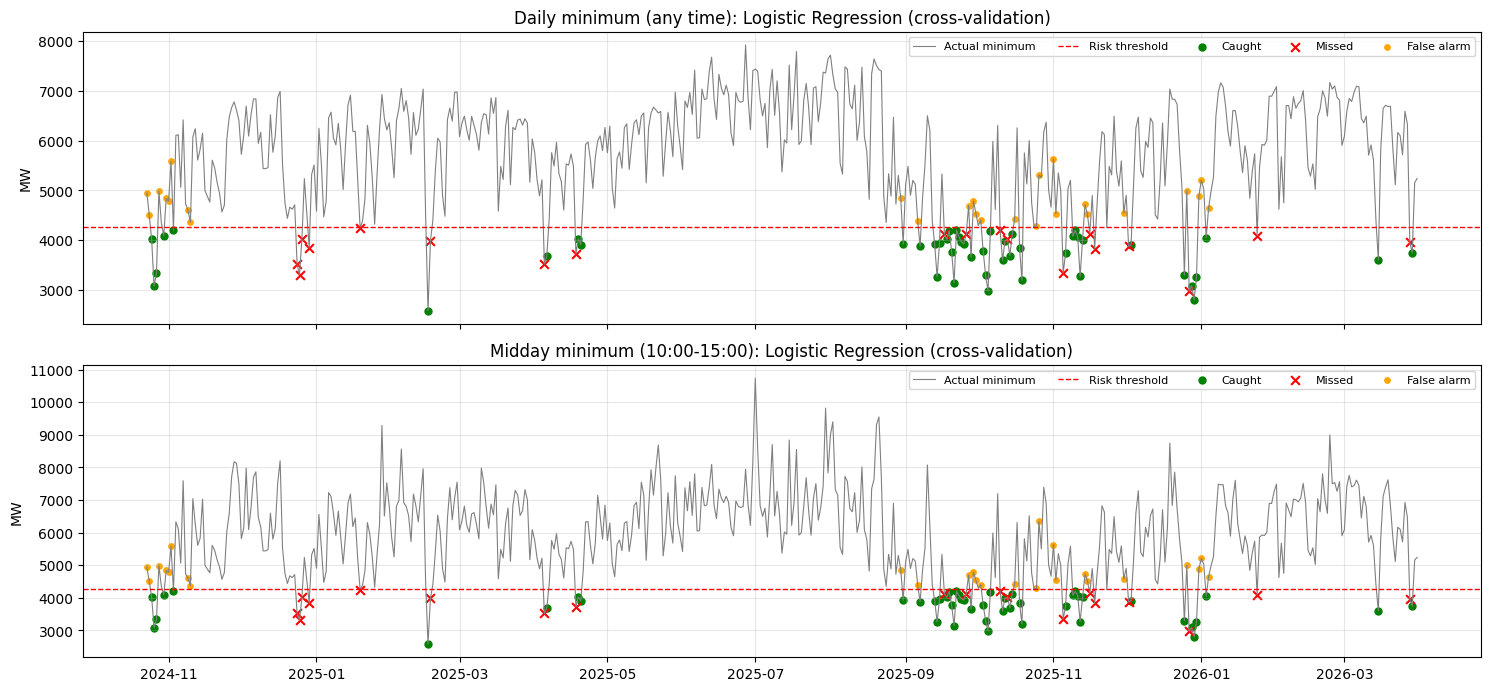

In [15]:
# Pick the best flagging approach per target by F1 (balances catching risky days against false alarms)
best_clf = {}
for t, tname in TARGETS.items():
    sub = clf_table[(clf_table["Target"] == tname) & ~clf_table["Model"].str.startswith("Baseline")]
    best_clf[t] = sub.iloc[0]["Model"]
    print(f"Best flagging approach for {tname}: {best_clf[t]} "
          f"(recall {sub.iloc[0]['Recall']:.2f}, precision {sub.iloc[0]['Precision']:.2f})")

# When during the year were risky days flagged and missed? (cross-validation period)
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, (t, tname) in zip(axes, TARGETS.items()):
    key = "Regression-based" if best_clf[t].startswith("Regression") else best_clf[t]
    flag = oof_flags[(t, key)]
    actual = train.loc[flag.index, t]
    risky = actual < THRESHOLDS[t]
    ax.plot(actual.index, actual, lw=0.8, color="grey", label="Actual minimum")
    ax.axhline(THRESHOLDS[t], color="red", ls="--", lw=1, label="Risk threshold")
    ax.scatter(actual.index[risky & (flag == 1)], actual[risky & (flag == 1)], color="green", s=25, label="Caught")
    ax.scatter(actual.index[risky & (flag == 0)], actual[risky & (flag == 0)], color="red", marker="x", s=40, label="Missed")
    ax.scatter(actual.index[~risky & (flag == 1)], actual[~risky & (flag == 1)], color="orange", s=15, label="False alarm")
    ax.set(title=f"{tname}: {best_clf[t]} (cross-validation)", ylabel="MW"); ax.legend(fontsize=8, ncol=5)
plt.tight_layout(); save_fig("04_risk_flags_cv.png"); plt.show()

## 13. Test-period comparison: April-June 2026
Fit every regression candidate and baseline on the 990 training days and report their test scores. The chosen model remains the one selected in Section 10. Reporting all test scores is diagnostic and must not be used to redefine the winner. This test period has already been inspected.


In [16]:
hold_rows, hold_pred = [], {}
for t, tname in TARGETS.items():
    candidates = {**make_baselines(t), **make_models(), "Gradient Boosting (tuned)": tuned[t]}
    for name in candidates:
        m = clone(candidates[name]).fit(X_train, train[t])
        p = pd.Series(m.predict(X_hold), index=hold.index)
        if name == best_reg[t]:
            hold_pred[t] = p
        hold_rows.append({"Target": tname, "Model": name, **regression_scores(hold[t], p)})

hold_table = pd.DataFrame(hold_rows).sort_values(["Target", "MAE (MW)"]).reset_index(drop=True)
hold_table.to_csv(os.path.join(RESULTS_DIR, "holdout_regression_results.csv"), index=False)
hold_table.round(2)

,Target,Model,MAE (MW),RMSE (MW),MAPE (%),R2
0,Daily minimum (any time),Linear Regression (Ridge),301.04,397.97,5.52,0.79
1,Daily minimum (any time),Gradient Boosting,333.81,435.87,6.12,0.74
2,Daily minimum (any time),Gradient Boosting (tuned),337.85,435.10,6.18,0.74
3,Daily minimum (any time),Random Forest,349.56,446.34,6.37,0.73
4,Daily minimum (any time),Baseline: same as yesterday,436.53,614.01,8.02,0.49
5,Daily minimum (any time),Baseline: seasonal average,459.28,611.21,8.63,0.50
6,Daily minimum (any time),Baseline: same day last week,577.09,739.15,10.23,0.26
7,Midday minimum (10:00-15:00),Linear Regression (Ridge),433.63,551.82,7.24,0.79
8,Midday minimum (10:00-15:00),Gradient Boosting,465.43,603.63,7.76,0.75
9,Midday minimum (10:00-15:00),Gradient Boosting (tuned),501.22,655.63,8.07,0.71


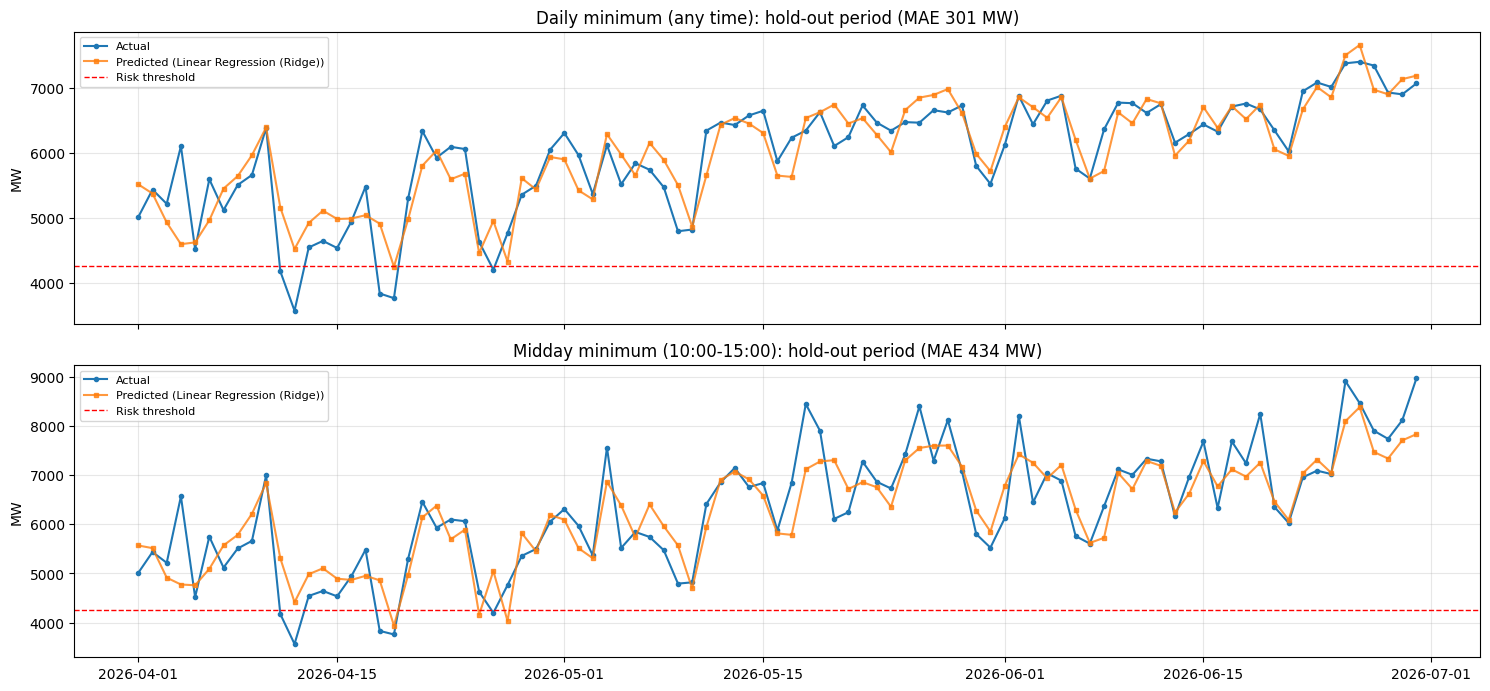

In [17]:
# Actual vs predicted minimum load over the hold-out period
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, (t, tname) in zip(axes, TARGETS.items()):
    ax.plot(hold.index, hold[t], marker="o", ms=3, label="Actual")
    ax.plot(hold.index, hold_pred[t], marker="s", ms=3, alpha=0.8, label=f"Predicted ({best_reg[t]})")
    ax.axhline(THRESHOLDS[t], color="red", ls="--", lw=1, label="Risk threshold")
    mae = mean_absolute_error(hold[t], hold_pred[t])
    ax.set(title=f"{tname}: hold-out period (MAE {mae:,.0f} MW)", ylabel="MW"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("05_holdout_actual_vs_predicted.png"); plt.show()

,Target,Model,Risky days,Caught,Missed,False alarms,Recall,Precision,F1,ROC-AUC
0,Daily minimum (any time),Logistic Regression,5,3,2,6,0.6,0.333,0.429,0.935
1,Midday minimum (10:00-15:00),Logistic Regression,5,3,2,6,0.6,0.333,0.429,0.935


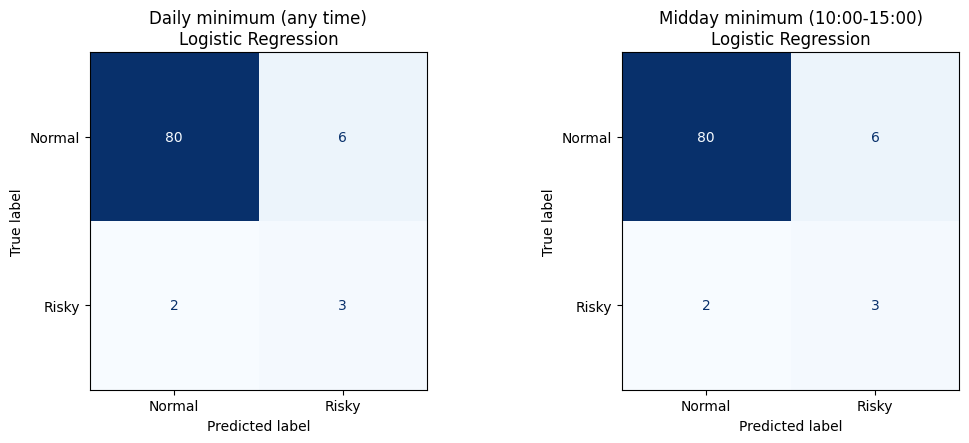

In [18]:
# Classification on the hold-out period
hold_clf_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (t, tname) in zip(axes, TARGETS.items()):
    thr = THRESHOLDS[t]
    y_hold_cls = (hold[t] < thr).astype(int)
    if best_clf[t].startswith("Regression"):
        flag = (hold_pred[t] < thr).astype(int); score = -hold_pred[t]
    else:
        m = clone(make_classifiers(t)[best_clf[t]]).fit(X_train, (train[t] < thr).astype(int))
        score = pd.Series(m.predict_proba(X_hold)[:, 1], index=hold.index)
        flag = (score >= 0.5).astype(int)
    hold_clf_rows.append({"Target": tname, "Model": best_clf[t], **classification_scores(y_hold_cls, flag, score)})
    ConfusionMatrixDisplay(confusion_matrix(y_hold_cls, flag, labels=[0, 1]),
                           display_labels=["Normal", "Risky"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=f"{tname}\n{best_clf[t]}"); ax.grid(False)
plt.tight_layout(); save_fig("06_holdout_confusion_matrices.png"); plt.show()

hold_clf_table = pd.DataFrame(hold_clf_rows)
hold_clf_table.to_csv(os.path.join(RESULTS_DIR, "holdout_classification_results.csv"), index=False)
hold_clf_table.round(3)

## 14. Feature importance
Report training-set permutation importance for the validation-selected models. Correlated seasonal and lag variables share information; importance is not a causal attribution.


Daily minimum (any time): seasonal features account for 8% of total importance
Midday minimum (10:00-15:00): seasonal features account for 6% of total importance


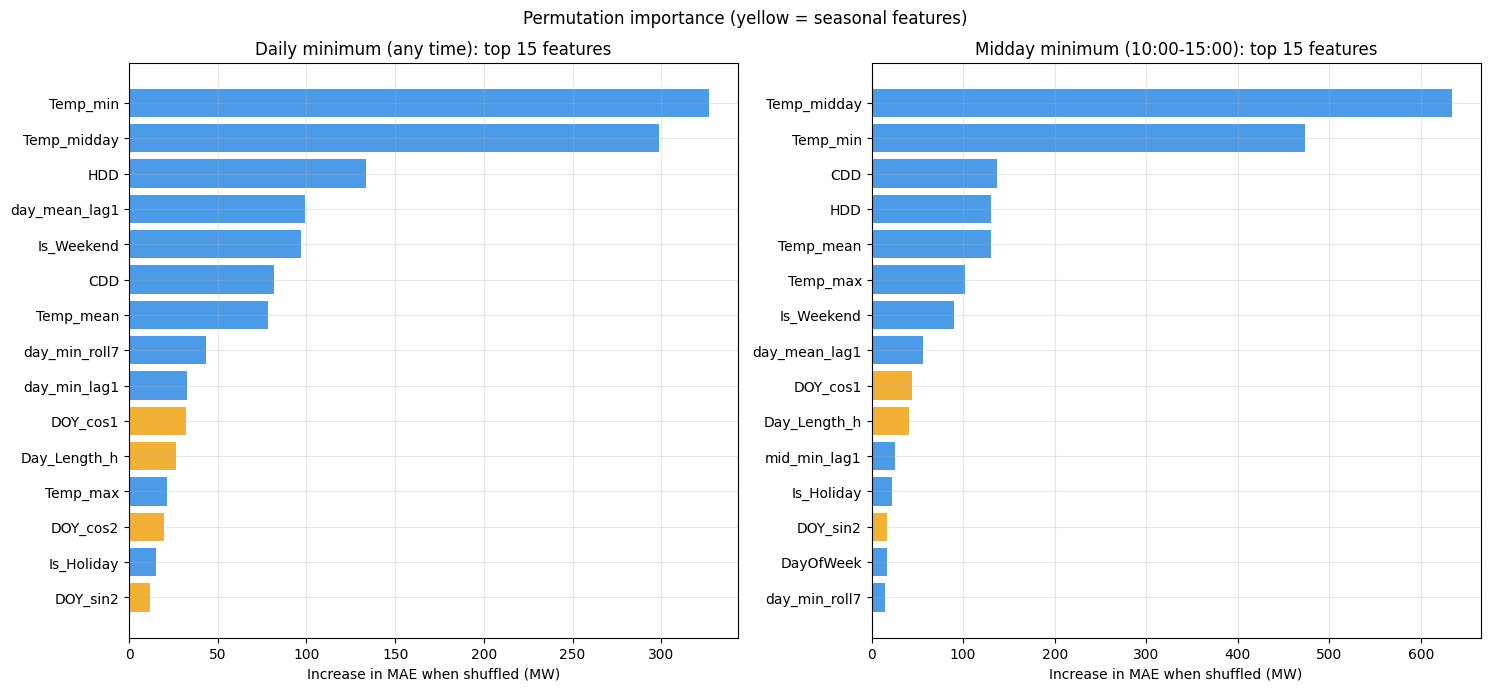

In [19]:
SEASONAL_FEATURES = {"DOY_sin1", "DOY_cos1", "DOY_sin2", "DOY_cos2", "Day_Length_h", "Month"}

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, (t, tname) in zip(axes, TARGETS.items()):
    candidates = {**make_models(), "Gradient Boosting (tuned)": tuned[t]}
    m = clone(candidates[best_reg[t]]).fit(X_train, train[t])
    imp = permutation_importance(m, X_train, train[t], n_repeats=10, scoring="neg_mean_absolute_error",
                                 random_state=RANDOM_STATE, n_jobs=-1)
    s = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(15)
    ax.barh(s.index, s.values, color=["#f2b134" if f in SEASONAL_FEATURES else "#4c9be8" for f in s.index])
    ax.set(title=f"{tname}: top 15 features", xlabel="Increase in MAE when shuffled (MW)")
    seasonal_share = imp.importances_mean[[f in SEASONAL_FEATURES for f in FEATURES]].clip(0).sum() / \
                     imp.importances_mean.clip(0).sum()
    print(f"{tname}: seasonal features account for {seasonal_share:.0%} of total importance")
fig.suptitle("Permutation importance (yellow = seasonal features)")
plt.tight_layout(); save_fig("07_feature_importance.png"); plt.show()

## 15. Results summary
Summarize validation-selected model performance. Keep the prior versions and their different validation schedules separate.


In [20]:
print("=" * 70)
print("RESULTS SUMMARY")
print("=" * 70)
print(f"Daily minimum fell between 10:00 and 15:00 on {midday_share:.0%} of days")
print(f"Training: {len(train)} days | Hold-out: {len(hold)} days ({HOLDOUT_START} to {hold.index.max():%Y-%m-%d})\n")
for t, tname in TARGETS.items():
    cv_best = cv_table[(cv_table["Target"] == tname) & (cv_table["Model"] == best_reg[t])].iloc[0]
    cv_seas = cv_table[(cv_table["Target"] == tname) & (cv_table["Model"] == "Baseline: seasonal average")].iloc[0]
    ho = hold_table[(hold_table["Target"] == tname) & (hold_table["Model"] == best_reg[t])].iloc[0]
    ho_base = hold_table[(hold_table["Target"] == tname) & hold_table["Model"].str.startswith("Baseline")]["MAE (MW)"].min()
    cl = clf_table[(clf_table["Target"] == tname) & (clf_table["Model"] == best_clf[t])].iloc[0]
    print(f"{tname}")
    print(f"  Regression: {best_reg[t]}")
    print(f"    CV MAE {cv_best['MAE (MW)']:.0f} MW vs seasonal-average baseline {cv_seas['MAE (MW)']:.0f} MW "
          f"({1 - cv_best['MAE (MW)'] / cv_seas['MAE (MW)']:.0%} better)")
    print(f"    Hold-out MAE {ho['MAE (MW)']:.0f} MW, MAPE {ho['MAPE (%)']:.1f}% "
          f"({1 - ho['MAE (MW)'] / ho_base:.0%} better than best baseline)")
    print(f"  Risk flag (below {THRESHOLDS[t]:,.0f} MW): {best_clf[t]}")
    print(f"    CV: caught {cl['Caught']} of {cl['Risky days']} risky days (recall {cl['Recall']:.0%}), "
          f"{cl['False alarms']} false alarms (precision {cl['Precision']:.0%})\n")
print(f"Figures and tables saved in '{RESULTS_DIR}/': {sorted(os.listdir(RESULTS_DIR))}")

RESULTS SUMMARY
Daily minimum fell between 10:00 and 15:00 on 62% of days
Training: 990 days | Hold-out: 91 days (2026-04-01 to 2026-06-30)

Daily minimum (any time)
  Regression: Linear Regression (Ridge)
    CV MAE 433 MW vs seasonal-average baseline 666 MW (35% better)
    Hold-out MAE 301 MW, MAPE 5.5% (31% better than best baseline)
  Risk flag (below 4,258 MW): Logistic Regression
    CV: caught 47 of 66 risky days (recall 71%), 26 false alarms (precision 64%)

Midday minimum (10:00-15:00)
  Regression: Linear Regression (Ridge)
    CV MAE 606 MW vs seasonal-average baseline 891 MW (32% better)
    Hold-out MAE 434 MW, MAPE 7.2% (40% better than best baseline)
  Risk flag (below 4,258 MW): Logistic Regression
    CV: caught 47 of 66 risky days (recall 71%), 26 false alarms (precision 64%)

Figures and tables saved in '/Users/maomengmeng/Desktop/codebase/NSW-demand-forecasting/experiments/results/combined_fixed_validation/': ['01_seasonality.png', '02_model_comparison.png', '03_er

## Limitations
- Observed weather substitutes for forecasts.
- Wind measurement definitions differ between the 2023 and original-source segments; source-specific missing values and earlier wind fills remain.
- January-June 2024 is absent. Lag windows reset at the gap.
- The April-June test period has already been examined; use a separate untouched test for final claims.
- Hyperparameters are tuned and compared on the same CV folds. Classification uses full-training quantile labels. Neither is nested validation.
- Low-load labels are statistical and do not establish system-security risk. Solar/cloud inputs are absent.
- Forecasts support human interpretation; they do not automatically authorize grid interventions.
